In [87]:
# Name : Margolliet
# E-mail : victor.margolliet@etu.univ-amu.fr

### default module import

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# for the data splitting
from sklearn.model_selection import train_test_split

### data generation

In [89]:
RANDOM_GEM = np.random.default_rng()

In [90]:
# code for the function to compute the gamma
def compute_gamma(kx,ky,chi_perp,chi_par,curvature):
    k_perp = np.sqrt(kx**2+ky**2)
    gamma_0 = np.sqrt(1-curvature)*ky/k_perp
    gamma = gamma_0 - chi_perp*ky**2-np.sqrt(chi_perp*chi_par)*ky
    return gamma


In [91]:
# code for the function to generate a data sample
def generate_sample():
  kx = RANDOM_GEM.uniform(np.pi/1024,np.pi)
  ky = RANDOM_GEM.uniform(np.pi/1024,np.pi/2)
  chi_perp = RANDOM_GEM.uniform(1e-4,1)
  chi_par = RANDOM_GEM.uniform(0,.5)
  curvature = RANDOM_GEM.uniform(0,1)
  return (kx,ky,chi_perp,chi_par,curvature, compute_gamma(kx, ky, chi_perp, chi_par, curvature))


In [92]:
# number of entries
N_runs = 1000

In [93]:
# put here the code to generate a list of N_runs data samples

data = []

for i in range(N_runs):
  data.append(generate_sample())

         kx        ky  chi_perp   chi_par  curvature     gamma
0  0.027431  0.199833  0.932644  0.094237   0.716434  0.431076
1  2.185243  0.884236  0.865191  0.131575   0.430093 -0.691643
2  2.630504  0.077512  0.462124  0.479943   0.222706 -0.013313
3  1.771871  0.692068  0.153640  0.397874   0.703746 -0.046673
4  0.681369  0.821201  0.515245  0.228386   0.701007 -0.208357


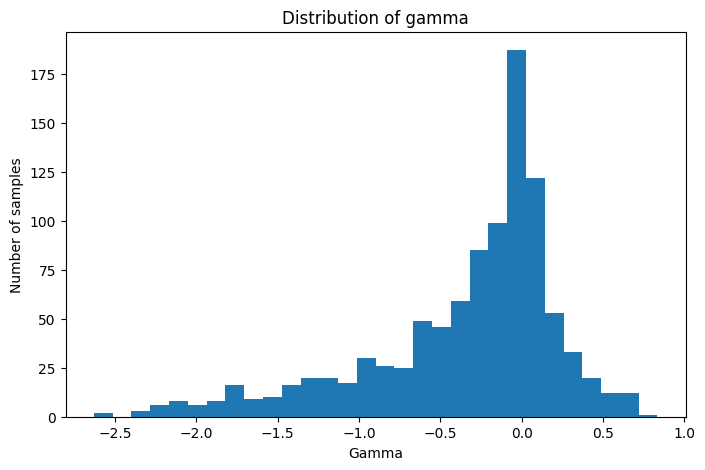

In [94]:
# and here for the conversion to a pandas dataframe

# we transform data into tableau to allow the computer to read the data

df_gamma = pd.DataFrame(data, columns=['kx','ky','chi_perp','chi_par','curvature','gamma'])

df_gamma = df_gamma.sample(frac=1).reset_index(drop=True)
#we randomly change the order of the data to prevent any order influence the model

print(df_gamma.head())
#we show to see if everything is ok

plt.figure(figsize=(8, 5))
plt.hist(df_gamma["gamma"], bins=30)
plt.xlabel("Gamma")
plt.ylabel("Number of samples")
plt.title("Distribution of gamma")
plt.show()

#we shwo the distribution of the growth rate on the simulations



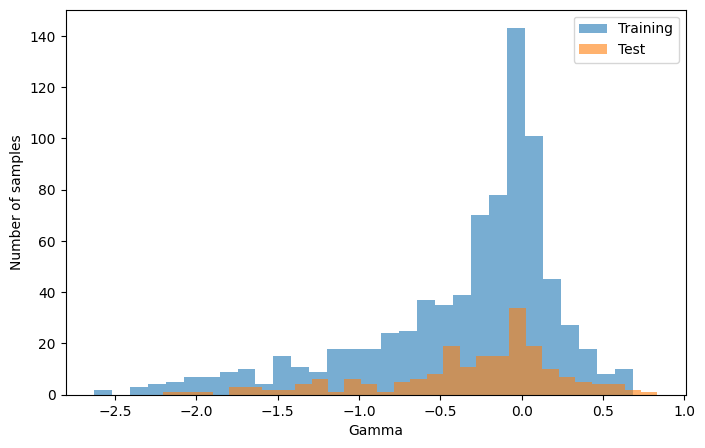

(800, 5)
(800,)
(200, 5)
(200,)


In [95]:
# Question 4 : Data Splitting

#we need separe training and test data for the model

#randomly 80 20 is commonly use in the field

train, test = train_test_split(df_gamma, test_size=0.2, random_state=42, shuffle=True)
#we split the data in

#in order to compare the distrib accros the diffenret distrib in the test and in the train set
#we can plot the garph

plt.figure(figsize=(8, 5))

plt.hist(train["gamma"], bins=30, alpha=0.6, label="Training")
plt.hist(test["gamma"], bins=30, alpha=0.6, label="Test")

plt.xlabel("Gamma")
plt.ylabel("Number of samples")
plt.legend()
plt.show()

#the final goal is to train the model to predict the growth rate with the initaila parmeter
#so we need to give him the 5 parmaeteer and the expected end y will be the growth rate


#so we separate both tableau
X_train = train.drop(columns=["gamma"]).to_numpy()
y_train = train["gamma"].to_numpy()

X_test = test.drop(columns=["gamma"]).to_numpy()
y_test = test["gamma"].to_numpy()

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)


# Section 1 - Simple Perceptron

### Necessary Imports

In [96]:
from keras.models import Sequential
from keras.layers import Input, Dense



### machine learning model generation

In [97]:
# create the model here

def keras_model(input_shape):
  model = Sequential()
  model.add(Input(shape=input_shape))
  model.add(Dense(8, activation='relu'))
  model.add(Dense(1))
  #model.compile(optimizer='adam', loss='mse') maybe after
  return model


  #dense 1 because we wnat one exist the growth rate ,
  #
 #to see the model
model = keras_model
model.summary()




Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 8)              │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57 (228.00 B)

 Trainable params: 57 (228.00 B)

 Non-trainable params: 0 (0.00 B)

### machine learning model compilation

In [98]:
# compile the model here
#it is here that we define how the model will learn

#need loss function and optimizer
model.compile(
    optimizer="adamw",
    loss="mse",
    metrics=["MeanSquaredError"]
)

#standard thing for both


In [99]:
# train the model here

history = model.fit(
    X_train,
    y_train,
    verbose=3,
    epochs=50
)

#verboise to show in real time the advancement of the trianning procedure
#epoch is the number of time the modle train on all the training data
#each time is improving but he need several epoch to be well trained


Epoch 1/50
Epoch 2/50
Epoch 3/50
Epoch 4/50
Epoch 5/50
Epoch 6/50
Epoch 7/50
Epoch 8/50
Epoch 9/50
Epoch 10/50
Epoch 11/50
Epoch 12/50
Epoch 13/50
Epoch 14/50
Epoch 15/50
Epoch 16/50
Epoch 17/50
Epoch 18/50
Epoch 19/50
Epoch 20/50
Epoch 21/50
Epoch 22/50
Epoch 23/50
Epoch 24/50
Epoch 25/50
Epoch 26/50
Epoch 27/50
Epoch 28/50
Epoch 29/50
Epoch 30/50
Epoch 31/50
Epoch 32/50
Epoch 33/50
Epoch 34/50
Epoch 35/50
Epoch 36/50
Epoch 37/50
Epoch 38/50
Epoch 39/50
Epoch 40/50
Epoch 41/50
Epoch 42/50
Epoch 43/50
Epoch 44/50
Epoch 45/50
Epoch 46/50
Epoch 47/50
Epoch 48/50
Epoch 49/50
Epoch 50/50


### Loss function plot

KeyError: 'mean_squared_error'

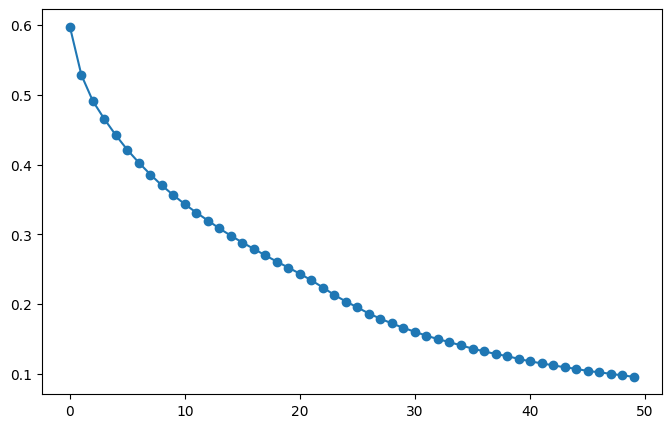

In [100]:
# plot the loss function

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], "o-", label="Training Loss")
plt.plot(history.history["mean_squared_error"], "--", label="MSE")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# the plot is good it is the expected plot that we should obtain
# it mean that the more the modle train , the more the error decrease, so the more it became accurate
#it tis exponenatial decay of the error function trhougth the epoch


### Prediction Comparison

In [101]:
### predict the values of gamma for the x_test data

y_pred = model.predict(X_test).flatten()

#we predict for the 200 test value and we flatten the data in tableau



7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


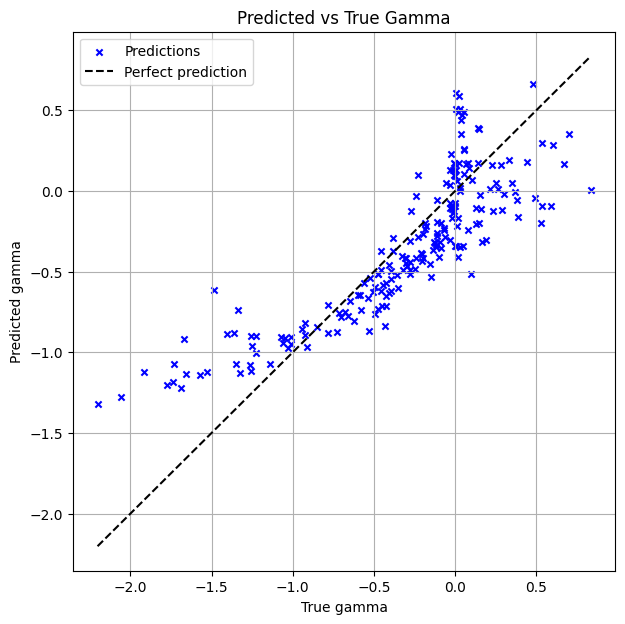

In [102]:
### make a plot to compare the predicted values with the expected ones


plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred, color="blue", marker="x", s=20,
            label="Predictions")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("True gamma")
plt.ylabel("Predicted gamma")
plt.title("Predicted vs True Gamma")

plt.legend()
plt.grid(True)
plt.show()

### Overfitting and Underfitting

Epoch 1/100
25/25 - 1s - 47ms/step - MeanSquaredError: 0.5988 - loss: 0.5988 - val_MeanSquaredError: 0.4521 - val_loss: 0.4521
Epoch 2/100
25/25 - 0s - 17ms/step - MeanSquaredError: 0.4552 - loss: 0.4552 - val_MeanSquaredError: 0.3761 - val_loss: 0.3761
Epoch 3/100
25/25 - 0s - 14ms/step - MeanSquaredError: 0.3975 - loss: 0.3975 - val_MeanSquaredError: 0.3480 - val_loss: 0.3480
Epoch 4/100
25/25 - 0s - 9ms/step - MeanSquaredError: 0.3676 - loss: 0.3676 - val_MeanSquaredError: 0.3235 - val_loss: 0.3235
Epoch 5/100
25/25 - 0s - 14ms/step - MeanSquaredError: 0.3410 - loss: 0.3410 - val_MeanSquaredError: 0.2998 - val_loss: 0.2998
Epoch 6/100
25/25 - 0s - 11ms/step - MeanSquaredError: 0.3183 - loss: 0.3183 - val_MeanSquaredError: 0.2804 - val_loss: 0.2804
Epoch 7/100
25/25 - 0s - 10ms/step - MeanSquaredError: 0.2978 - loss: 0.2978 - val_MeanSquaredError: 0.2632 - val_loss: 0.2632
Epoch 8/100
25/25 - 0s - 10ms/step - MeanSquaredError: 0.2782 - loss: 0.2782 - val_MeanSquaredError: 0.2457 - va

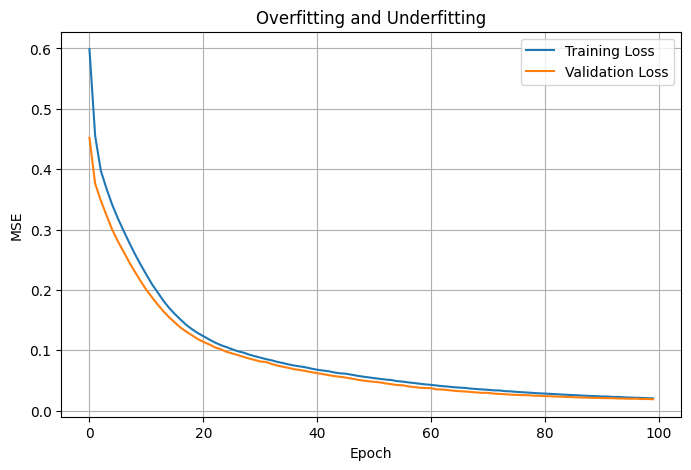

In [106]:
# Create a new model
model_val = Sequential()

model_val.add(Input(shape=(5,)))
model_val.add(Dense(8, activation="relu"))
model_val.add(Dense(1))

# Compile the model
model_val.compile(
    optimizer="adamw",
    loss="mse",
    metrics=["MeanSquaredError"]
)

# Train the model
history_val = model_val.fit(
    X_train,
    y_train,
    verbose=2,
    epochs=100,
    validation_data=(X_test, y_test)
)

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history_val.history["loss"], label="Training Loss")
plt.plot(history_val.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Overfitting and Underfitting")

plt.legend()
plt.grid(True)
plt.show()




#overfitting happend when the model start to learn by heart the data set , it is bad because if we shaow data otside the data set ,he will gess randomly and be not accurate
#when the traing curve go donw but at the same time the test curve go up , it mean the model performe verry well in training but not in testing , so the model just learn the data set and overfitting
#by plotting the 2 curve we can see if the modle overfitte
# and undefitting is the oposite the training curve do not go down enough the modle do not leanr enought from the training part and he gess predicted value randomly to
# the real risk is overfitting because we always want the model to have the best accuracy so we fid him with lot of data and put lot of epcohc


# Section 2 - Multi Layer Perceptron

### Model creation

In [107]:
def create_mlp(input_dim):

    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(32, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    return model


# Create the MLP
model_mlp = create_mlp(X_train.shape[1])

# Compile the MLP
model_mlp.compile(
    optimizer="adamw",
    loss="mse",
    metrics=["MeanSquaredError"]
)

# Display architecture
model_mlp.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,281 (5.00 KB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 0 (0.00 B)

### Model training

In [111]:
import time

start = time.perf_counter()

history_mlp = model_mlp.fit(
    X_train,
    y_train,
    epochs=100,
    verbose=2,
    validation_data=(X_test, y_test)
)

training_time = time.perf_counter() - start

print(f"Training time: {training_time:.2f} s")

Epoch 1/100
25/25 - 0s - 7ms/step - MeanSquaredError: 0.0019 - loss: 0.0019 - val_MeanSquaredError: 0.0047 - val_loss: 0.0047
Epoch 2/100
25/25 - 0s - 6ms/step - MeanSquaredError: 0.0017 - loss: 0.0017 - val_MeanSquaredError: 0.0042 - val_loss: 0.0042
Epoch 3/100
25/25 - 0s - 6ms/step - MeanSquaredError: 0.0017 - loss: 0.0017 - val_MeanSquaredError: 0.0038 - val_loss: 0.0038
Epoch 4/100
25/25 - 0s - 6ms/step - MeanSquaredError: 0.0016 - loss: 0.0016 - val_MeanSquaredError: 0.0039 - val_loss: 0.0039
Epoch 5/100
25/25 - 0s - 6ms/step - MeanSquaredError: 0.0017 - loss: 0.0017 - val_MeanSquaredError: 0.0042 - val_loss: 0.0042
Epoch 6/100
25/25 - 0s - 7ms/step - MeanSquaredError: 0.0017 - loss: 0.0017 - val_MeanSquaredError: 0.0037 - val_loss: 0.0037
Epoch 7/100
25/25 - 0s - 6ms/step - MeanSquaredError: 0.0015 - loss: 0.0015 - val_MeanSquaredError: 0.0037 - val_loss: 0.0037
Epoch 8/100
25/25 - 0s - 6ms/step - MeanSquaredError: 0.0017 - loss: 0.0017 - val_MeanSquaredError: 0.0037 - val_loss:

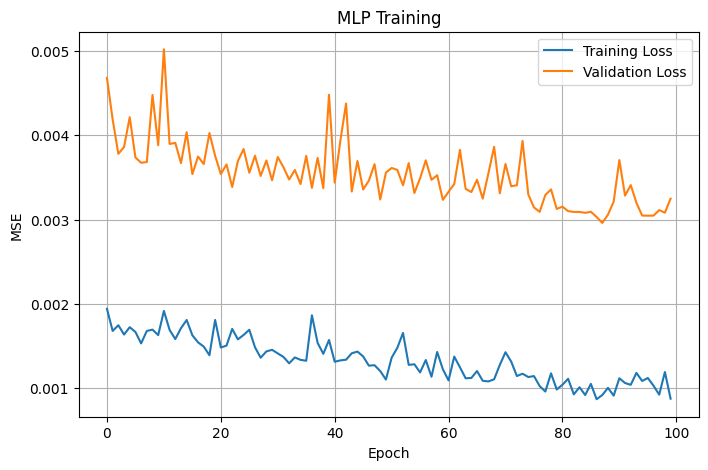

In [112]:
plt.figure(figsize=(8, 5))

plt.plot(history_mlp.history["loss"], label="Training Loss")
plt.plot(history_mlp.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MLP Training")
plt.legend()
plt.grid(True)
plt.show()

#both curve decrease this is good but not in the classique exponanatial ways ,
#we will see if it is a probleme or not latter if we have bad resust or not

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


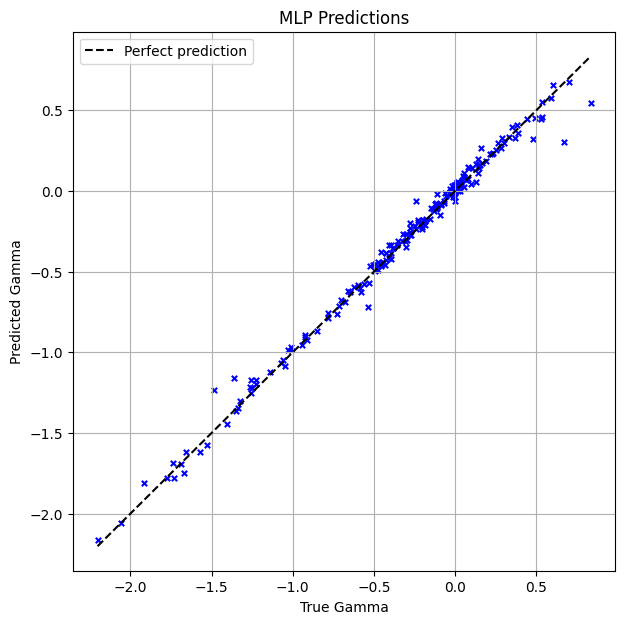

In [113]:
y_pred_mlp = model_mlp.predict(X_test).flatten()

plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred_mlp, marker="x", s=15, color="blue")

limits = [
    min(y_test.min(), y_pred_mlp.min()),
    max(y_test.max(), y_pred_mlp.max())
]

plt.plot(limits, limits, "k--", label="Perfect prediction")

plt.xlabel("True Gamma")
plt.ylabel("Predicted Gamma")
plt.title("MLP Predictions")
plt.legend()
plt.grid(True)
plt.show()

#here good model predicted vs true is lienar some point verry far the y=x but it ok , from the last one , it is a very big improvement


### Influence of Batch Size

In [115]:
import time

batch_sizes = [16, 32, 64, 128]

histories = {}
training_times = {}
final_mse = {}

# Same initial weights for all models
initial_weights = create_mlp(5).get_weights()

for batch in batch_sizes:

    model_batch = create_mlp(5)
    model_batch.set_weights(initial_weights)

    model_batch.compile(
        optimizer="adamw",
        loss="mse"
    )

    start = time.perf_counter()

    history = model_batch.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=batch,
        validation_data=(X_test, y_test),
        verbose=0
    )

    training_times[batch] = time.perf_counter() - start
    histories[batch] = history.history
    final_mse[batch] = history.history["val_loss"][-1]

    print(f"Batch {batch}: MSE = {final_mse[batch]:.6f}, "
          f"Time = {training_times[batch]:.2f} s")

Batch 16: MSE = 0.004796, Time = 14.84 s
Batch 32: MSE = 0.004308, Time = 9.25 s
Batch 64: MSE = 0.007383, Time = 7.52 s
Batch 128: MSE = 0.012844, Time = 9.49 s


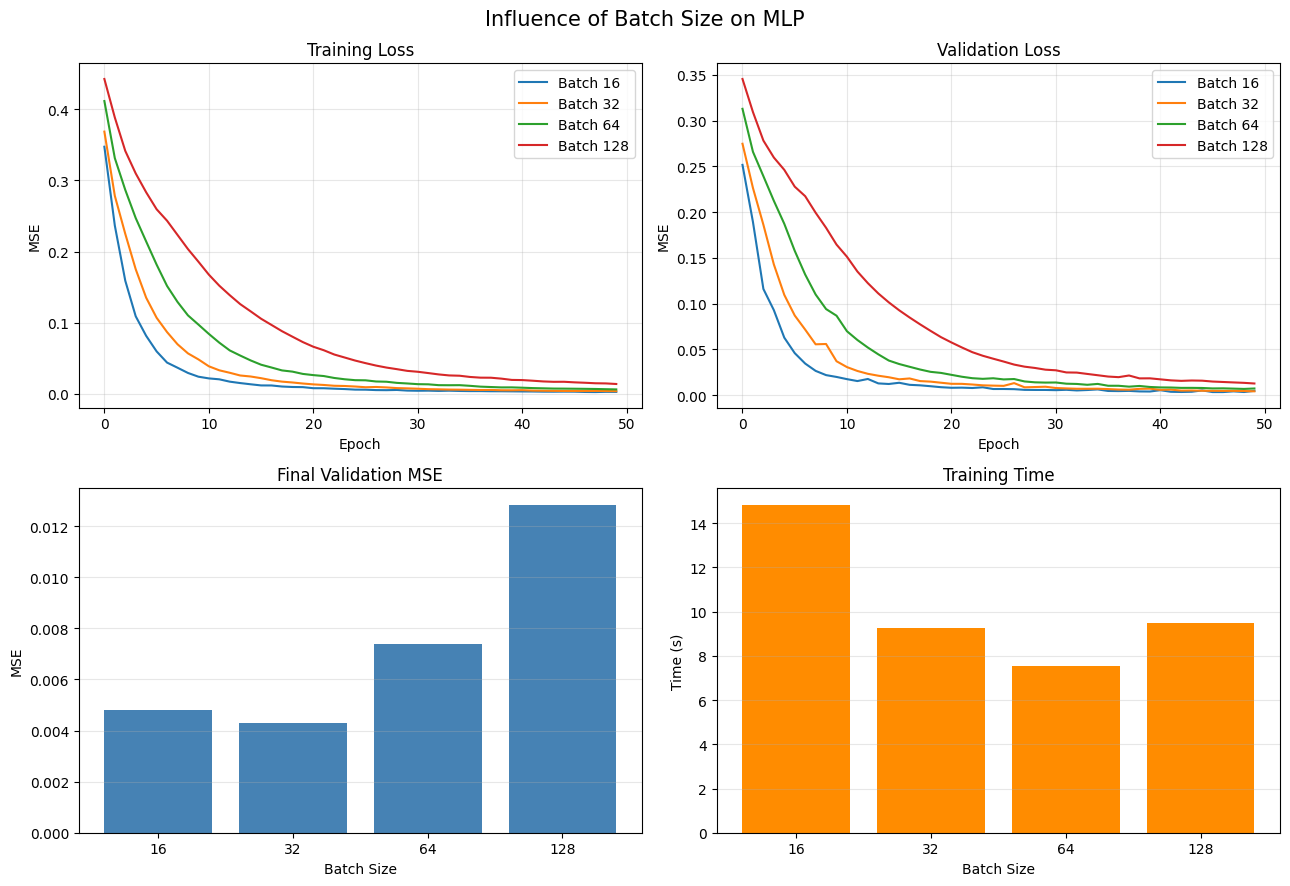

In [116]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. Training Loss
for batch in batch_sizes:
    ax[0, 0].plot(
        histories[batch]["loss"],
        label=f"Batch {batch}"
    )

ax[0, 0].set_title("Training Loss")
ax[0, 0].set_xlabel("Epoch")
ax[0, 0].set_ylabel("MSE")
ax[0, 0].legend()
ax[0, 0].grid(alpha=0.3)


# 2. Validation Loss
for batch in batch_sizes:
    ax[0, 1].plot(
        histories[batch]["val_loss"],
        label=f"Batch {batch}"
    )

ax[0, 1].set_title("Validation Loss")
ax[0, 1].set_xlabel("Epoch")
ax[0, 1].set_ylabel("MSE")
ax[0, 1].legend()
ax[0, 1].grid(alpha=0.3)


# 3. Final Validation MSE
ax[1, 0].bar(
    [str(b) for b in batch_sizes],
    [final_mse[b] for b in batch_sizes],
    color="steelblue"
)

ax[1, 0].set_title("Final Validation MSE")
ax[1, 0].set_xlabel("Batch Size")
ax[1, 0].set_ylabel("MSE")
ax[1, 0].grid(axis="y", alpha=0.3)


# 4. Training Time
ax[1, 1].bar(
    [str(b) for b in batch_sizes],
    [training_times[b] for b in batch_sizes],
    color="darkorange"
)

ax[1, 1].set_title("Training Time")
ax[1, 1].set_xlabel("Batch Size")
ax[1, 1].set_ylabel("Time (s)")
ax[1, 1].grid(axis="y", alpha=0.3)

plt.suptitle("Influence of Batch Size on MLP", fontsize=15)
plt.tight_layout()
plt.show()

In [117]:
df_results = pd.DataFrame({
    "Batch Size": batch_sizes,
    "Final MSE": [final_mse[b] for b in batch_sizes],
    "Training Time (s)": [training_times[b] for b in batch_sizes]
})

print(df_results.to_string(index=False))

best_batch = min(final_mse, key=final_mse.get)

print(f"\nBest batch size: {best_batch}")

 Batch Size  Final MSE  Training Time (s)
         16   0.004796          14.835535
         32   0.004308           9.253436
         64   0.007383           7.519597
        128   0.012844           9.489758

Best batch size: 32


In [ ]:
#so here he have see the impact of the batch size , no we will see the other thing


new section like to test batchnor and dropout


In [119]:
from keras.layers import Dropout, BatchNormalization
from keras.utils import set_random_seed

def create_dropout_model(input_dim, dropout_rate=0.2, use_bn=True):

    model = Sequential()
    model.add(Input(shape=(input_dim,)))

    model.add(Dense(64, activation="relu"))

    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))

    model.add(Dense(32, activation="relu"))

    if use_bn:
        model.add(BatchNormalization())

    model.add(Dense(1))

    model.compile(
        optimizer="adamw",
        loss="mse"
    )

    return model

In [120]:
import time

dropout_rates = [0.0, 0.1, 0.3, 0.5]
bn_options = [True, False]

dropout_histories = {}
dropout_results = []
dropout_models = {}

for use_bn in bn_options:

    for rate in dropout_rates:

        print(f"Training: Dropout={rate}, BatchNorm={use_bn}")

        # Reproducible initialization
        set_random_seed(42)

        model_d = create_dropout_model(
            input_dim=X_train.shape[1],
            dropout_rate=rate,
            use_bn=use_bn
        )

        start = time.perf_counter()

        history_d = model_d.fit(
            X_train,
            y_train,
            epochs=50,
            batch_size=32,
            validation_data=(X_test, y_test),
            verbose=0
        )

        elapsed = time.perf_counter() - start

        key = (use_bn, rate)

        dropout_models[key] = model_d
        dropout_histories[key] = history_d.history

        dropout_results.append({
            "BatchNorm": use_bn,
            "Dropout": rate,
            "Training MSE": history_d.history["loss"][-1],
            "Validation MSE": history_d.history["val_loss"][-1],
            "Time (s)": elapsed
        })

        print(f"Validation MSE: {history_d.history['val_loss'][-1]:.6f}")
        print(f"Training time: {elapsed:.2f} s\n")

Training: Dropout=0.0, BatchNorm=True
Validation MSE: 0.009025
Training time: 17.01 s

Training: Dropout=0.1, BatchNorm=True
Validation MSE: 0.025870
Training time: 9.26 s

Training: Dropout=0.3, BatchNorm=True
Validation MSE: 0.066702
Training time: 10.38 s

Training: Dropout=0.5, BatchNorm=True
Validation MSE: 0.155547
Training time: 10.76 s

Training: Dropout=0.0, BatchNorm=False
Validation MSE: 0.003691
Training time: 9.40 s

Training: Dropout=0.1, BatchNorm=False
Validation MSE: 0.007079
Training time: 8.25 s

Training: Dropout=0.3, BatchNorm=False
Validation MSE: 0.010790
Training time: 10.92 s

Training: Dropout=0.5, BatchNorm=False
Validation MSE: 0.018558
Training time: 9.45 s



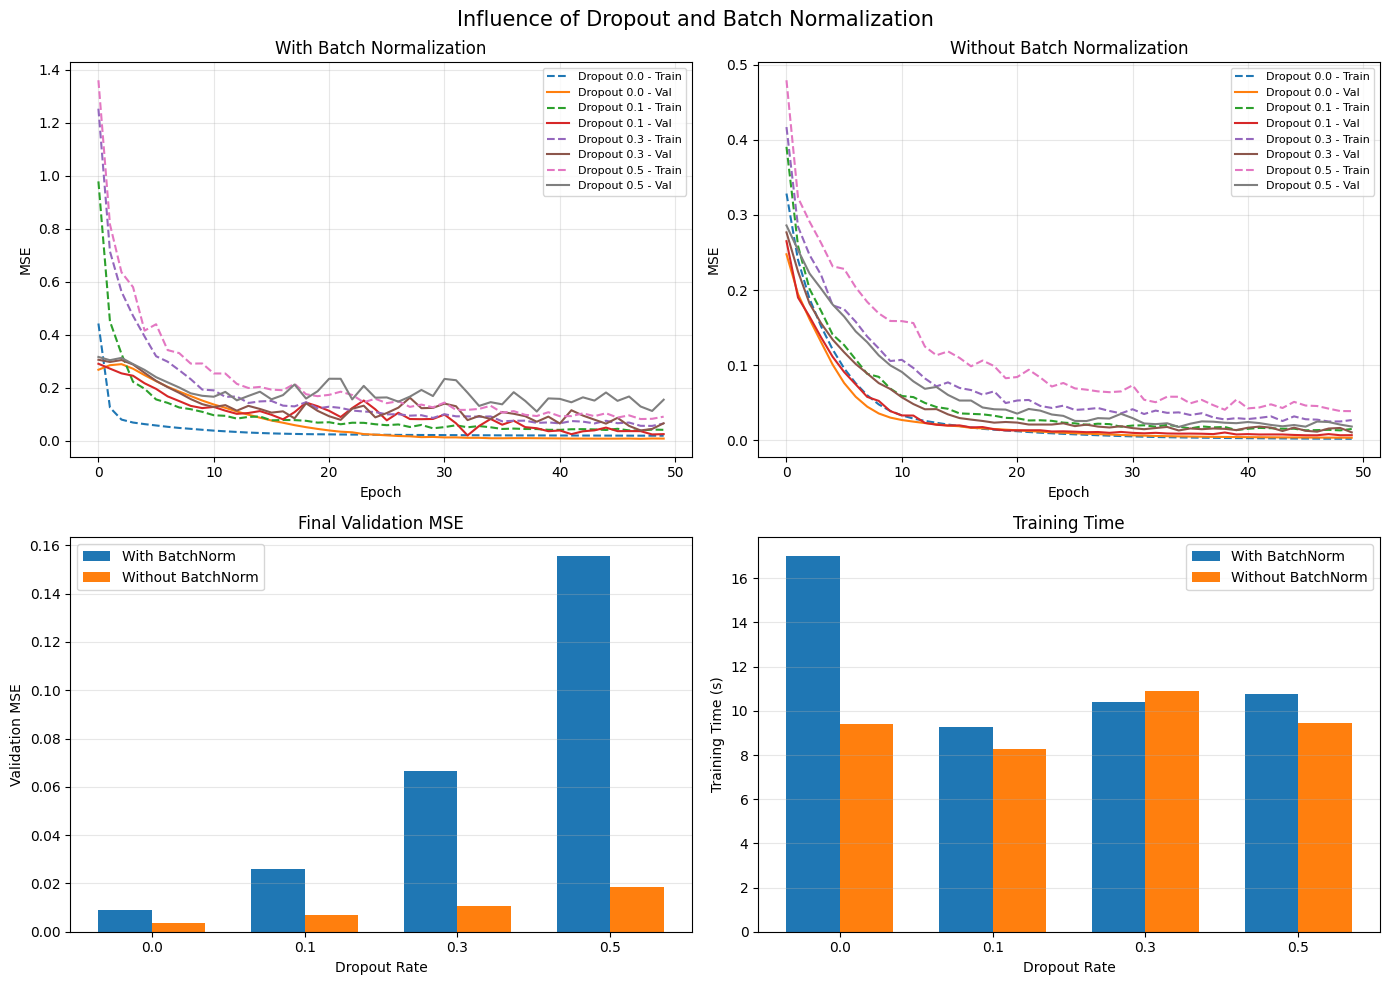

In [121]:
#we do same comaprasion plot that previoulsy

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

#  Loss with batchNorm
for rate in dropout_rates:

    h = dropout_histories[(True, rate)]

    ax[0, 0].plot(
        h["loss"],
        linestyle="--",
        label=f"Dropout {rate} - Train"
    )

    ax[0, 0].plot(
        h["val_loss"],
        label=f"Dropout {rate} - Val"
    )

ax[0, 0].set_title("With Batch Normalization")
ax[0, 0].set_xlabel("Epoch")
ax[0, 0].set_ylabel("MSE")
ax[0, 0].legend(fontsize=8)
ax[0, 0].grid(alpha=0.3)


#loss no batch
for rate in dropout_rates:

    h = dropout_histories[(False, rate)]

    ax[0, 1].plot(
        h["loss"],
        linestyle="--",
        label=f"Dropout {rate} - Train"
    )

    ax[0, 1].plot(
        h["val_loss"],
        label=f"Dropout {rate} - Val"
    )

ax[0, 1].set_title("Without Batch Normalization")
ax[0, 1].set_xlabel("Epoch")
ax[0, 1].set_ylabel("MSE")
ax[0, 1].legend(fontsize=8)
ax[0, 1].grid(alpha=0.3)


# 3. Final Validation MSE
x = np.arange(len(dropout_rates))
width = 0.35

mse_bn = [
    dropout_histories[(True, r)]["val_loss"][-1]
    for r in dropout_rates
]

mse_no_bn = [
    dropout_histories[(False, r)]["val_loss"][-1]
    for r in dropout_rates
]

ax[1, 0].bar(
    x - width/2, mse_bn, width,
    label="With BatchNorm"
)

ax[1, 0].bar(
    x + width/2, mse_no_bn, width,
    label="Without BatchNorm"
)

ax[1, 0].set_xticks(x)
ax[1, 0].set_xticklabels(dropout_rates)
ax[1, 0].set_xlabel("Dropout Rate")
ax[1, 0].set_ylabel("Validation MSE")
ax[1, 0].set_title("Final Validation MSE")
ax[1, 0].legend()
ax[1, 0].grid(axis="y", alpha=0.3)


# training time even if here we dont care
times_bn = [
    next(d["Time (s)"] for d in dropout_results
         if d["BatchNorm"] and d["Dropout"] == r)
    for r in dropout_rates
]

times_no_bn = [
    next(d["Time (s)"] for d in dropout_results
         if not d["BatchNorm"] and d["Dropout"] == r)
    for r in dropout_rates
]

ax[1, 1].bar(
    x - width/2, times_bn, width,
    label="With BatchNorm"
)

ax[1, 1].bar(
    x + width/2, times_no_bn, width,
    label="Without BatchNorm"
)

ax[1, 1].set_xticks(x)
ax[1, 1].set_xticklabels(dropout_rates)
ax[1, 1].set_xlabel("Dropout Rate")
ax[1, 1].set_ylabel("Training Time (s)")
ax[1, 1].set_title("Training Time")
ax[1, 1].legend()
ax[1, 1].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Influence of Dropout and Batch Normalization",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [122]:


df_dropout = pd.DataFrame(dropout_results)

print("\n===== DROPOUT AND BATCHNORM COMPARISON =====")
print(df_dropout.to_string(index=False))

best_idx = df_dropout["Validation MSE"].idxmin()
best_row = df_dropout.loc[best_idx]

best_rate = float(best_row["Dropout"])
best_bn = bool(best_row["BatchNorm"])

best_model = dropout_models[(best_bn, best_rate)]

print("\n===== BEST CONFIGURATION =====")
print(f"Dropout Rate   : {best_rate}")
print(f"BatchNorm      : {best_bn}")
print(f"Validation MSE : {best_row['Validation MSE']:.6f}")
print(f"Training Time  : {best_row['Time (s)']:.2f} s")

best_model.summary()


===== DROPOUT AND BATCHNORM COMPARISON =====
 BatchNorm  Dropout  Training MSE  Validation MSE  Time (s)
      True      0.0      0.019848        0.009025 17.005175
      True      0.1      0.042033        0.025870  9.264635
      True      0.3      0.065836        0.066702 10.379724
      True      0.5      0.091642        0.155547 10.757128
     False      0.0      0.002250        0.003691  9.395308
     False      0.1      0.015308        0.007079  8.254165
     False      0.3      0.027156        0.010790 10.916170
     False      0.5      0.039051        0.018558  9.451256

===== BEST CONFIGURATION =====
Dropout Rate   : 0.0
BatchNorm      : False
Validation MSE : 0.003691
Training Time  : 9.40 s


Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_53 (Dense)                │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,493 (29.27 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,996 (19.52 KB)

In [123]:
# we have find that dropout drecease the preformance of the model of course ,
#but it increase it ways to generalaize data
#dropout allow the modle to not relly on single neurone but on a more rafine combinaison of neurone

#for this data set dropout and batch norm are not necessary the data set is to short or to simple to use this type of tools on it ,
#but it is neededd for more complex data


#dropout help to not overfitting the data, but he reduce the model learning, here no signe of overfitting so he made the model undefitte


#batch norm add operation and can increase the time of the thing ,
# here small network so maby not necessary to use it

#the traing is above the test it is ok since we use bact norm and dropiut it is logical

